In [1]:
import numpy as np
import pandas as pd
from mlxtend.plotting import plot_decision_regions

In [2]:
df = pd.DataFrame()

In [3]:
df['X1'] = [1,2,3,4,5,6,6,7,9,9]
df['X2'] = [5,3,6,8,1,9,5,8,9,2]
df['label'] =  [1,1,0,1,0,1,0,1,0,0]

In [4]:
df

,X1,X2,label
0,1,5,1
1,2,3,1
2,3,6,0
3,4,8,1
4,5,1,0
5,6,9,1
6,6,5,0
7,7,8,1
8,9,9,0
9,9,2,0


<Axes: xlabel='X1', ylabel='X2'>

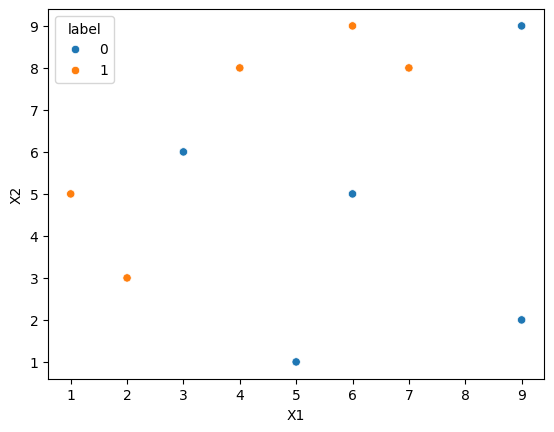

In [5]:
import seaborn as sns
sns.scatterplot(x=df['X1'], y=df['X2'], hue=df['label'])

In [6]:
df['weights'] = 1/df.shape[0]

In [7]:
df

,X1,X2,label,weights
0,1,5,1,0.1
1,2,3,1,0.1
2,3,6,0,0.1
3,4,8,1,0.1
4,5,1,0,0.1
5,6,9,1,0.1
6,6,5,0,0.1
7,7,8,1,0.1
8,9,9,0,0.1
9,9,2,0,0.1


In [8]:
from sklearn.tree import DecisionTreeClassifier

In [9]:
dt1 = DecisionTreeClassifier(max_depth = 1)

In [10]:
X = df.iloc[:,0:2].values
Y = df.iloc[:,2].values

In [11]:
# Training the first model
dt1.fit(X, Y)

DecisionTreeClassifier(max_depth=1)

[Text(0.5, 0.75, 'x[1] <= 2.5\ngini = 0.5\nsamples = 10\nvalue = [5, 5]'),
 Text(0.25, 0.25, 'gini = 0.0\nsamples = 2\nvalue = [2, 0]'),
 Text(0.375, 0.5, 'True  '),
 Text(0.75, 0.25, 'gini = 0.469\nsamples = 8\nvalue = [3, 5]'),
 Text(0.625, 0.5, '  False')]

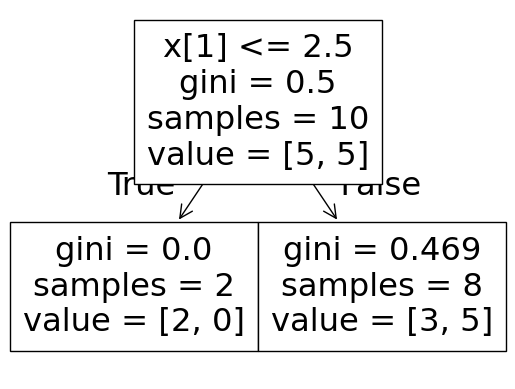

In [12]:
from sklearn.tree import plot_tree
plot_tree(dt1)

<Axes: >

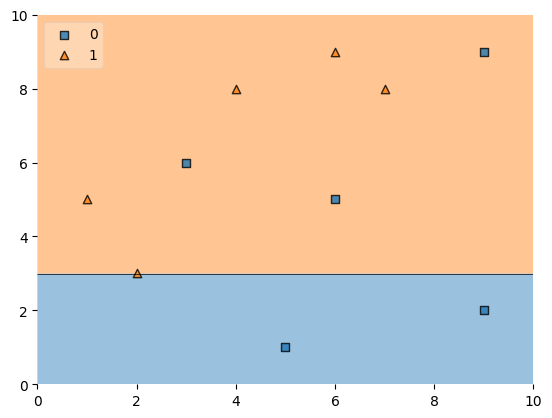

In [13]:
plot_decision_regions(X, Y, clf=dt1, legend=2)
# legend = controls whether and where the class label box (color guide) appears on the decision boundary plot.

In [14]:
df['Y_pred'] = dt1.predict(X)

In [15]:
df

,X1,X2,label,weights,Y_pred
0,1,5,1,0.1,1
1,2,3,1,0.1,1
2,3,6,0,0.1,1
3,4,8,1,0.1,1
4,5,1,0,0.1,0
5,6,9,1,0.1,1
6,6,5,0,0.1,1
7,7,8,1,0.1,1
8,9,9,0,0.1,1
9,9,2,0,0.1,0


In [16]:
# If error in dataset is 0 then in denumerator it will be ( error + 0.00001) 
def calculate_model_weight(error):
    return 0.5*np.log((1-error)/(error))
    

In [17]:
# Calculating model weight 
alpha1 = calculate_model_weight(0.3)
alpha1

np.float64(0.42364893019360184)

In [18]:
# Now Updating the weights:
def update_row_weights(row, alpha=0.42364893019360184):
    
    if row['label'] == row['Y_pred']:
        return row['weights'] * np.exp(-alpha)

    else:
        return row['weights'] * np.exp(alpha)
    

In [19]:
df['updated_weights'] = df.apply(update_row_weights, axis=1)

In [20]:
df

,X1,X2,label,weights,Y_pred,updated_weights
0,1,5,1,0.1,1,0.065465
1,2,3,1,0.1,1,0.065465
2,3,6,0,0.1,1,0.152753
3,4,8,1,0.1,1,0.065465
4,5,1,0,0.1,0,0.065465
5,6,9,1,0.1,1,0.065465
6,6,5,0,0.1,1,0.152753
7,7,8,1,0.1,1,0.065465
8,9,9,0,0.1,1,0.152753
9,9,2,0,0.1,0,0.065465


In [21]:
df['updated_weights'].sum()

np.float64(0.9165151389911682)

In [22]:
df['normalized_weights'] = df['updated_weights']/df['updated_weights'].sum()

In [23]:
df

,X1,X2,label,weights,Y_pred,updated_weights,normalized_weights
0,1,5,1,0.1,1,0.065465,0.071429
1,2,3,1,0.1,1,0.065465,0.071429
2,3,6,0,0.1,1,0.152753,0.166667
3,4,8,1,0.1,1,0.065465,0.071429
4,5,1,0,0.1,0,0.065465,0.071429
5,6,9,1,0.1,1,0.065465,0.071429
6,6,5,0,0.1,1,0.152753,0.166667
7,7,8,1,0.1,1,0.065465,0.071429
8,9,9,0,0.1,1,0.152753,0.166667
9,9,2,0,0.1,0,0.065465,0.071429


In [24]:
df['normalized_weights'].sum()

np.float64(0.9999999999999999)

In [25]:
# Creating upper and lower range
df['cumsum_upper'] = np.cumsum(df['normalized_weights'])

In [26]:
df['cumsum_lower'] = df['cumsum_upper'] - df['normalized_weights']

In [27]:
df [['X1', 'X2', 'label', 'weights', 'Y_pred', 'normalized_weights', 'cumsum_lower',  'cumsum_upper']]

,X1,X2,label,weights,Y_pred,normalized_weights,cumsum_lower,cumsum_upper
0,1,5,1,0.1,1,0.071429,0.000000,0.071429
1,2,3,1,0.1,1,0.071429,0.071429,0.142857
2,3,6,0,0.1,1,0.166667,0.142857,0.309524
3,4,8,1,0.1,1,0.071429,0.309524,0.380952
4,5,1,0,0.1,0,0.071429,0.380952,0.452381
5,6,9,1,0.1,1,0.071429,0.452381,0.523810
6,6,5,0,0.1,1,0.166667,0.523810,0.690476
7,7,8,1,0.1,1,0.071429,0.690476,0.761905
8,9,9,0,0.1,1,0.166667,0.761905,0.928571
9,9,2,0,0.1,0,0.071429,0.928571,1.000000


In [28]:
def create_new_dataset(df):
    indices = []

    for i in range(df.shape[0]):
        a = np.random.random()
        for index, row in df.iterrows():
            if row['cumsum_upper']>a and a>row['cumsum_lower']:
                indices.append(index)
    return indices

In [29]:
index_values = create_new_dataset(df)
index_values

[6, 6, 6, 6, 2, 6, 3, 5, 9, 2]

---

In [30]:
second_df = df.iloc[index_values,[0,1,2,3]]

In [31]:
second_df

,X1,X2,label,weights
6,6,5,0,0.1
6,6,5,0,0.1
6,6,5,0,0.1
6,6,5,0,0.1
2,3,6,0,0.1
6,6,5,0,0.1
3,4,8,1,0.1
5,6,9,1,0.1
9,9,2,0,0.1
2,3,6,0,0.1


In [32]:
dt2 = DecisionTreeClassifier(max_depth=1)

In [33]:
X = second_df.iloc[:,0:2].values
Y = second_df.iloc[:,2].values

In [34]:
dt2.fit(X, Y)

DecisionTreeClassifier(max_depth=1)

[Text(0.5, 0.75, 'x[1] <= 7.0\ngini = 0.32\nsamples = 10\nvalue = [8, 2]'),
 Text(0.25, 0.25, 'gini = 0.0\nsamples = 8\nvalue = [8, 0]'),
 Text(0.375, 0.5, 'True  '),
 Text(0.75, 0.25, 'gini = 0.0\nsamples = 2\nvalue = [0, 2]'),
 Text(0.625, 0.5, '  False')]

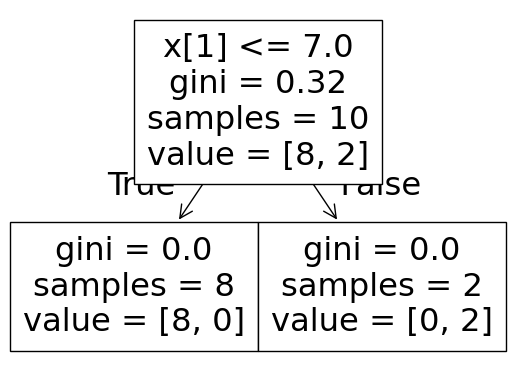

In [35]:
plot_tree(dt2)

<Axes: >

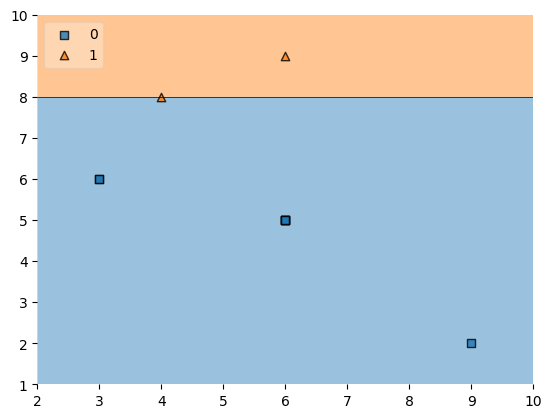

In [36]:
plot_decision_regions(X, Y, clf=dt2, legend=2)

In [37]:
second_df['Y_pred'] = dt2.predict(X)

In [38]:
second_df

,X1,X2,label,weights,Y_pred
6,6,5,0,0.1,0
6,6,5,0,0.1,0
6,6,5,0,0.1,0
6,6,5,0,0.1,0
2,3,6,0,0.1,0
6,6,5,0,0.1,0
3,4,8,1,0.1,1
5,6,9,1,0.1,1
9,9,2,0,0.1,0
2,3,6,0,0.1,0


In [39]:
alpha2 = calculate_model_weight(0.1)

In [40]:
alpha2

np.float64(1.0986122886681098)

In [41]:
# Updating the weights 

def update_row_weights(row, alpha = 1.0986122886681098):
    
  if row['label'] == row['Y_pred']:
    return row['weights'] * np.exp(-alpha)
      
  else:
    return row['weights'] * np.exp(alpha)

In [42]:
second_df['updated_weights'] = second_df.apply(update_row_weights, axis=1)

In [43]:
second_df

,X1,X2,label,weights,Y_pred,updated_weights
6,6,5,0,0.1,0,0.033333
6,6,5,0,0.1,0,0.033333
6,6,5,0,0.1,0,0.033333
6,6,5,0,0.1,0,0.033333
2,3,6,0,0.1,0,0.033333
6,6,5,0,0.1,0,0.033333
3,4,8,1,0.1,1,0.033333
5,6,9,1,0.1,1,0.033333
9,9,2,0,0.1,0,0.033333
2,3,6,0,0.1,0,0.033333


In [44]:
second_df['updated_weights'].sum()

np.float64(0.3333333333333333)

In [45]:
second_df['nomalized_weights'] = second_df['updated_weights']/second_df['updated_weights'].sum()

In [46]:
second_df['nomalized_weights'].sum()

np.float64(1.0)

In [47]:
# Creating the range :
second_df['cumsum_upper'] = np.cumsum(second_df['nomalized_weights'])
second_df['cumsum_lower'] = (second_df['cumsum_upper'] - second_df['nomalized_weights'])

In [48]:
second_df[['X1','X2','label','weights','Y_pred','nomalized_weights','cumsum_lower','cumsum_upper']]

,X1,X2,label,weights,Y_pred,nomalized_weights,cumsum_lower,cumsum_upper
6,6,5,0,0.1,0,0.1,0.0,0.1
6,6,5,0,0.1,0,0.1,0.1,0.2
6,6,5,0,0.1,0,0.1,0.2,0.3
6,6,5,0,0.1,0,0.1,0.3,0.4
2,3,6,0,0.1,0,0.1,0.4,0.5
6,6,5,0,0.1,0,0.1,0.5,0.6
3,4,8,1,0.1,1,0.1,0.6,0.7
5,6,9,1,0.1,1,0.1,0.7,0.8
9,9,2,0,0.1,0,0.1,0.8,0.9
2,3,6,0,0.1,0,0.1,0.9,1.0


In [49]:
index_values = create_new_dataset(second_df)
index_values

[9, 6, 6, 6, 2, 6, 2, 2, 6, 6]

---

In [50]:
third_df = second_df.iloc[index_values, [0,1,2,3]]  # selecting starting 4 columns

In [51]:
third_df

,X1,X2,label,weights
2,3,6,0,0.1
3,4,8,1,0.1
3,4,8,1,0.1
3,4,8,1,0.1
6,6,5,0,0.1
3,4,8,1,0.1
6,6,5,0,0.1
6,6,5,0,0.1
3,4,8,1,0.1
3,4,8,1,0.1


In [52]:
dt3 = DecisionTreeClassifier(max_depth=1)

X = second_df.iloc[:,0:2].values
Y = second_df.iloc[:,2].values

dt3.fit(X,Y)

DecisionTreeClassifier(max_depth=1)

<Axes: >

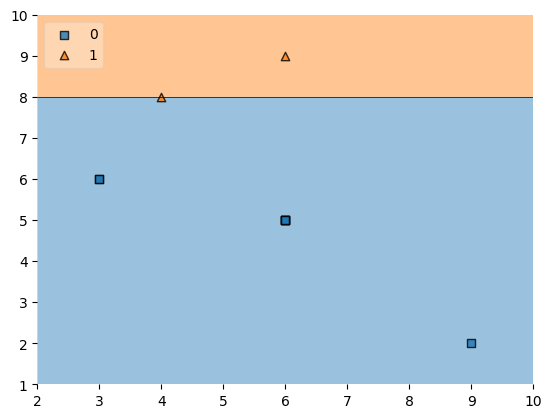

In [53]:
plot_decision_regions(X, Y, clf=dt3, legend=2)

In [54]:
third_df['Y_pred'] = dt3.predict(X)

In [55]:
third_df

,X1,X2,label,weights,Y_pred
2,3,6,0,0.1,0
3,4,8,1,0.1,0
3,4,8,1,0.1,0
3,4,8,1,0.1,0
6,6,5,0,0.1,0
3,4,8,1,0.1,0
6,6,5,0,0.1,1
6,6,5,0,0.1,1
3,4,8,1,0.1,0
3,4,8,1,0.1,0


In [56]:
alpha3 = calculate_model_weight(0.1)
alpha3

np.float64(1.0986122886681098)

In [57]:
print(alpha1, alpha2, alpha3)

0.42364893019360184 1.0986122886681098 1.0986122886681098


### Prediction

In [58]:
# Taking the datapoints from dataset to predict 
query = np.array([1,5]).reshape(1,2)
dt1.predict(query)

array([1])

In [59]:
dt2.predict(query)

array([0])

In [60]:
dt3.predict(query)

array([0])

In [61]:
alpha1*(1) + alpha2*(-1) + alpha3*(-1)

np.float64(-1.7735756471426178)

In [62]:
np.sign(-1.77)

np.float64(-1.0)

In [63]:
query = np.array([9,9]).reshape(1,2)
dt1.predict(query)

array([1])

In [64]:
dt2.predict(query)

array([1])

In [65]:
dt3.predict(query)

array([1])

In [66]:
alpha1*(-1) + alpha2*(1) + alpha3*(1)

np.float64(1.7735756471426178)

In [67]:
np.sign(1.77)

np.float64(1.0)